# CMU Machine Learning with Large Datasets

## Homework 4 — MinHash Deduplication with Polars Cloud

**Student handout**


### Instructions

Complete every section marked `TODO` or `<FILL IN>`. Pass the local checks before
running Part 3. Set your Polars Cloud workspace and S3 output directory in Part 0;
you will need a workspace and an S3 bucket for this assignment.

Before submitting, restart the kernel and run all cells in order.


In [ ]:
# Who did you collaborate with on this assignment?
# If no one, leave the list empty; otherwise list your collaborators below.
# TODO: Fill in your collaborators.
collaborators = []


In [ ]:
assert isinstance(collaborators, list) and all(
    isinstance(name, str) for name in collaborators
), "List your collaborators as strings, or use [] if you worked alone."


## Part 0: Preliminaries and Data Loading

### Overview

In this assignment, you will use MinHash and locality-sensitive hashing (LSH)
to deduplicate an LLM pretraining corpus with Polars and Polars Cloud.
This is our last homework using Polars: think of it as the Polars "final boss."

### Dataset

We will use [jrast/web-corpus-text-raw](https://huggingface.co/datasets/jrast/web-corpus-text-raw),
a collection of about 5 million English-language documents from Common Crawl.
We have handled document selection, downloading, and HTML-to-text conversion.

Test and debug on successively larger datasets: `VERY_SMALL`, `SMALL`, `LARGE`,
then `FULL`. The smaller sizes select a prefix of the corpus. Use `FULL` for
the final run.

### Notebook outline

0. **Preliminaries and Data Loading**
1. **Approximate Nearest Neighbor Search**: shingles, MinHash, and LSH candidates
2. **Corpus Deduplication**: graph edges, connected components, and representatives
3. **Running on Polars Cloud**: compute graph edges, propagate labels to convergence, and save survivors


In [ ]:
# Run if needed, then restart the kernel.
# %pip install --quiet polars==1.43.2 polars-cloud==0.10.0 numpy matplotlib


In [ ]:
import hashlib
from uuid import uuid4

import numpy as np
import polars as pl

assert pl.__version__ == "1.43.2", "Install polars==1.43.2 and restart the kernel."


In [ ]:
VERY_SMALL = 1_000
SMALL = 10_000
LARGE = 100_000
FULL = None

# Pick your dataset. Use FULL for the final run; start with VERY_SMALL for testing.
dataset = VERY_SMALL

# Set these before running Part 3.
WORKSPACE = ""  # Your Polars Cloud workspace
OUTPUT_ROOT = ""  # e.g. "s3://your-bucket/hw4"
CLUSTER_SIZE = 4  # Use 32 or more workers for the final run.

SHINGLE_LENGTH = 9
SEED = 137
NUM_BANDS = 4
BAND_SIZE = 64
NUM_HASHES = NUM_BANDS * BAND_SIZE
MAX_LABEL_UPDATES = 100

REPO = "jrast/web-corpus-text-raw"
REVISION = "fc01ebd56acf579c874d76b1fd348310cd1b26d0"


In [ ]:
documents = pl.scan_parquet(
    f"hf://datasets/{REPO}@{REVISION}/data/**/*.parquet"
).select("id", "text")

if dataset is not None:
    documents = documents.head(dataset)


## Part 1: Approximate Nearest Neighbor Search

### Part 1.1: Extract character shingles

Represent each text as the set of its overlapping `k`-character substrings.
Preserve case and whitespace. Repeated shingles appear once. A text shorter than
`k` has an empty shingle set. Assume `k > 0`.


<details>
<summary><strong>Hint: expected input and output</strong></summary>

**Example input**

```python
shingle("banana", k=3)
```

**Expected output** (set order is irrelevant)

```python
{"ban", "ana", "nan"}
```

`shingle("hi", k=3)` returns `set()`.

</details>


In [ ]:
def shingle(text, k=SHINGLE_LENGTH):
    """Return the distinct overlapping character shingles.

    Args:
        text (str): document text.
        k (int): number of characters in each shingle.
    Returns:
        set[str]: all distinct k-character substrings.
    """
    # TODO: Replace <FILL IN> with your implementation.
    # return <FILL IN>

    raise NotImplementedError("Complete this exercise.")


In [ ]:
"""Check the shingling example."""
assert shingle("banana", k=3) == {"ban", "ana", "nan"}

def _check_shingle_edge_cases():
    cases = [
        ("", 3, set()),
        ("hi", 3, set()),
        ("abc", 3, {"abc"}),
        ("aaaaa", 2, {"aa"}),
        ("Aa A", 2, {"Aa", "a ", " A"}),
        ("a\nb", 2, {"a\n", "\nb"}),
        ("aba", 1, {"a", "b"}),
    ]
    for text, k, expected in cases:
        actual = shingle(text, k=k)
        assert isinstance(actual, set), "shingle must return a set"
        assert actual == expected, f"Incorrect shingles for {text!r}, k={k}"

_check_shingle_edge_cases()


### Part 1.2: Compute MinHash signatures

For shingle set $S$, signature position $i$ stores $\min_{s \in S} h_i(s)$.
Use the provided `stable_hash` and define
`h_i(s) = (stable_hash(s) ^ keys[i]) % MAX_HASH`, where `^` is bitwise XOR.
Generate the keys with `np.random.RandomState(seed).randint(1, MAX_HASH, size=num_hashes)`.

Initialize every position to `MAX_HASH`, then update the minima as you process
the shingles. Return an `int32` array of length `num_hashes`; an empty set leaves
all entries at `MAX_HASH`. Assume `num_hashes > 0`.


**Useful NumPy APIs:**

- [`numpy.minimum`](https://numpy.org/doc/stable/reference/generated/numpy.minimum.html) updates the minimum at every position.
- [`RandomState.randint`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.RandomState.randint.html) generates the same keys from a fixed seed.


**Worked example: one minimum per signature position**

**Example input**

```python
minhash_signature_from_shingles({"alpha", "beta", "gamma"}, num_hashes=3, seed=137)
```

Read down each hash column. Its minimum becomes one signature entry:

| Shingle | Hash 0 | Hash 1 | Hash 2 |
| --- | ---: | ---: | ---: |
| `alpha` | 1,933,683,968 | 57,888,504 | 340,481,425 |
| `beta` | 647,706,260 | 1,453,970,796 | 1,100,074,501 |
| `gamma` | 926,231,587 | 1,191,694,299 | 1,346,360,498 |
| **Minimum** | **647,706,260** | **57,888,504** | **340,481,425** |

**Expected output**

```python
array([647706260, 57888504, 340481425], dtype=int32)
```

For an empty set and three hashes, return `[MAX_HASH, MAX_HASH, MAX_HASH]` as an
`int32` array.


In [ ]:
# Provided: a deterministic 31-bit shingle hash.
MAX_HASH = 2**31 - 1

def stable_hash(value):
    return int(hashlib.md5(str(value).encode("utf-8")).hexdigest(), 16) % MAX_HASH


In [ ]:
def minhash_signature_from_shingles(shingles_set, num_hashes=NUM_HASHES, seed=SEED):
    """Compute one minimum for each seeded hash function.

    Args:
        shingles_set (set[str]): distinct shingles in one document.
        num_hashes (int): number of signature positions.
        seed (int): seed shared across all documents.
    Returns:
        np.ndarray: shape (num_hashes,), dtype np.int32.
    """
    # TODO: Replace <FILL IN> with your implementation.
    # return <FILL IN>

    raise NotImplementedError("Complete this exercise.")


In [ ]:
"""Check the worked MinHash example."""
_expected = np.array([647706260, 57888504, 340481425], dtype=np.int32)
_signature = minhash_signature_from_shingles({"alpha", "beta", "gamma"}, 3, 137)
np.testing.assert_array_equal(_signature, _expected)
assert _signature.dtype == np.int32

def _check_signature_contract():
    empty = minhash_signature_from_shingles(set(), num_hashes=5, seed=0)
    assert isinstance(empty, np.ndarray), "Return a NumPy array"
    assert empty.shape == (5,) and empty.dtype == np.int32, "Check signature shape and dtype"
    np.testing.assert_array_equal(empty, np.full(5, MAX_HASH, dtype=np.int32))

    items = {"alpha", "beta", "gamma"}
    before = items.copy()
    actual = minhash_signature_from_shingles(items, num_hashes=5, seed=0)
    assert isinstance(actual, np.ndarray) and actual.dtype == np.int32
    np.testing.assert_array_equal(
        actual, np.array([245271922, 354758127, 905388457, 253415562, 414135451], dtype=np.int32),
        err_msg="Honor both num_hashes and seed",
    )
    np.testing.assert_array_equal(
        actual, minhash_signature_from_shingles(items, num_hashes=5, seed=0),
        err_msg="Repeated calls with the same input and seed must agree",
    )
    assert items == before, "Do not mutate the input shingle set"

_check_signature_contract()


#### Provided: how many hash functions?

For ideal independent MinHash functions, the matching fraction estimates Jaccard
similarity $J$, with standard error $\sqrt{J(1-J)/n}$. The plot below compares exact
Jaccard with estimates from 16, 64, and 256 signature positions for 150 synthetic
pairs. Each set has 100 distinct nine-character shingle labels.

This local illustration calls your signature function. A reference plot is shown;
rerun it after Part 1.2. The corpus pipeline uses a fixed 256 hashes arranged in 4 bands of 64 hashes each.


In [ ]:
# Provided: synthetic pairs with different amounts of shared content.
rng = np.random.default_rng(SEED)
true_jaccard = []
signature_pairs = []
for pair in range(150):
    shared_count = int(rng.integers(0, 101))
    universe = [f"{pair * 300 + i:09d}" for i in rng.permutation(300)]
    left = set(universe[:100])
    right = set(universe[:shared_count] + universe[100:200 - shared_count])
    true_jaccard.append(len(left & right) / len(left | right))
    signature_pairs.append((
        minhash_signature_from_shingles(left, num_hashes=256),
        minhash_signature_from_shingles(right, num_hashes=256),
    ))


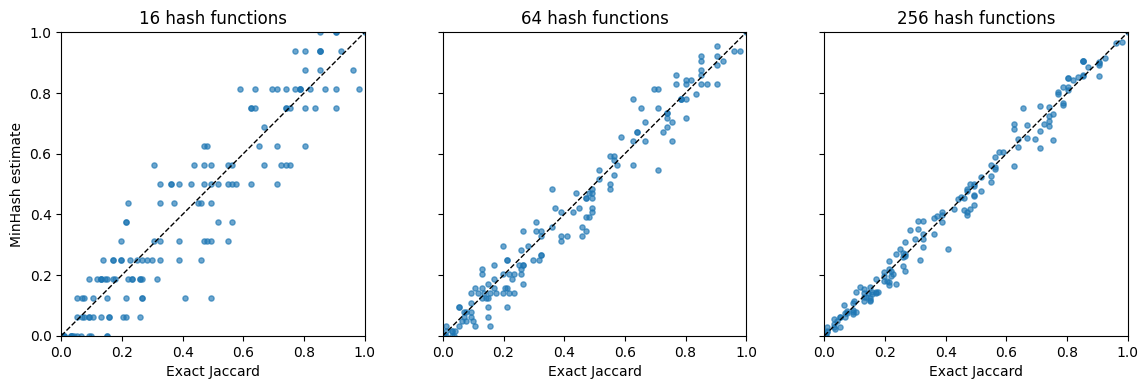

In [ ]:
# Provided: compare prefixes of the same signatures.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True)
for ax, n in zip(axes, [16, 64, 256]):
    estimates = [np.mean(a[:n] == b[:n]) for a, b in signature_pairs]
    ax.scatter(true_jaccard, estimates, s=14, alpha=0.65)
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set(title=f"{n} hash functions", xlabel="Exact Jaccard", xlim=(0, 1), ylim=(0, 1))
    ax.set_aspect("equal")
axes[0].set_ylabel("MinHash estimate")
fig.tight_layout()
plt.show()


#### Provided: the same MinHash computation, faster

For the corpus, use the implementation below. It uses optimized batch operations.


In [ ]:
def fast_minhash_signature(shingles, num_hashes=256, seed=137):
    """Compute the same signature using blocks of hash-function × shingle values."""
    # Worker-executed code carries its own imports and constants.
    import hashlib
    import numpy as np

    max_hash = 2**31 - 1
    block_size = 2_048
    keys = np.random.RandomState(seed).randint(1, max_hash, size=num_hashes).astype(np.uint32)
    signature = np.full(num_hashes, max_hash, dtype=np.uint32)
    hashes = np.fromiter(
        (int(hashlib.md5(str(item).encode("utf-8")).hexdigest(), 16) % max_hash
         for item in shingles),
        dtype=np.uint32,
        count=len(shingles),
    )
    for start in range(0, len(hashes), block_size):
        # One row per key, one column per shingle.
        values = keys[:, None] ^ hashes[None, start:start + block_size]
        # XOR stays in [0, max_hash]; only max_hash changes under % max_hash.
        values[values == max_hash] = 0
        signature = np.minimum(signature, values.min(axis=1))
    return signature.astype(np.int32)


In [ ]:
"""Check that the faster implementation matches your reference function."""
for _test_items in [set(), {"alpha", "beta"}, {str(i) for i in range(2051)}]:
    np.testing.assert_array_equal(
        minhash_signature_from_shingles(_test_items, 32, 137),
        fast_minhash_signature(_test_items, 32, 137),
    )

# Check non-default seeds and signature lengths, including a singleton set.
for _items in [{"only"}, {"é🙂", "Aa ", "a\nb"}]:
    for _seed in [0, 42]:
        for _length in [1, 7]:
            _actual = minhash_signature_from_shingles(_items, _length, _seed)
            assert isinstance(_actual, np.ndarray) and _actual.dtype == np.int32
            np.testing.assert_array_equal(
                _actual, fast_minhash_signature(_items, _length, _seed),
                err_msg=f"Reference/fast mismatch: seed={_seed}, num_hashes={_length}",
            )


### Part 1.3: Apply shingling and MinHash to documents

Build a lazy `id, signature` table from the corpus's `id, text` table.
Each document can be processed independently, so use `map_batches` with
`is_elementwise=True`.

Filter out texts shorter than `k`, then apply your shingling function and the
provided faster signature function to each remaining text. The excluded
documents will still be retained in the final corpus.


**Useful Polars APIs:**

- [`Expr.map_batches`](https://docs.pola.rs/api/python/stable/reference/expressions/api/polars.Expr.map_batches.html) applies a Python function to a Series; set the return dtype.
- [`filter`](https://docs.pola.rs/api/python/stable/reference/lazyframe/api/polars.LazyFrame.filter.html) excludes texts too short to have shingles.


<details>
<summary><strong>Hint: expected input and output</strong></summary>

**Example input** (`k=3, num_hashes=3, seed=137`)

| `id: String` | `text: String` |
| --- | --- |
| doc_a | alpha |
| doc_b | hi |

**Expected output**

| `id: String` | `signature: List(Int32)` |
| --- | --- |
| doc_a | `[330711975, 281013744, 126351001]` |

The second text has no 3-character shingles and is omitted.

</details>


In [ ]:
def build_signatures(documents, k=SHINGLE_LENGTH, num_hashes=NUM_HASHES, seed=SEED):
    """Build a lazy table of document signatures.

    Args:
        documents (pl.LazyFrame): id (String), text (String).
        k (int): shingle length.
        num_hashes (int): signature length.
        seed (int): shared signature seed.
    Returns:
        pl.LazyFrame: id (String), signature (List(Int32)).
    """
    # TODO: Replace <FILL IN> with your implementation.
    # def hash_text_batch(texts):
    #   <FILL IN>
    # return <FILL IN>

    raise NotImplementedError("Complete this exercise.")


In [ ]:
"""Check document signatures against the example above."""
_test_documents = pl.LazyFrame({"id": ["doc_a", "doc_b"], "text": ["alpha", "hi"]})
_test_signatures = build_signatures(_test_documents, k=3, num_hashes=3, seed=137).collect()
assert _test_signatures.to_dict(as_series=False) == {
    "id": ["doc_a"], "signature": [[330711975, 281013744, 126351001]],
}

def _check_signature_tables():
    source = pl.LazyFrame({
        "id": ["z", "a", "unicode", "short", "empty"],
        "text": ["abc", "abc", "é🙂a", "hi", ""],
    })
    query = build_signatures(source, k=3, num_hashes=7, seed=0)
    assert isinstance(query, pl.LazyFrame), "build_signatures must remain lazy"
    actual = query.collect().sort("id")
    assert actual.schema == {"id": pl.String, "signature": pl.List(pl.Int32)}
    expected = [
        ("a", fast_minhash_signature({"abc"}, 7, 0).tolist()),
        ("unicode", fast_minhash_signature({"é🙂a"}, 7, 0).tolist()),
        ("z", fast_minhash_signature({"abc"}, 7, 0).tolist()),
    ]
    assert actual.rows() == expected, "Preserve IDs, character lengths, seed, and duplicate texts"
    reversed_result = build_signatures(source.collect().reverse().lazy(), 3, 7, 0).collect()
    assert reversed_result.sort("id").equals(actual), "Signatures must not depend on row order"
    for subset in [source.limit(0), source.filter(pl.col("id").is_in(["short", "empty"]))]:
        result = build_signatures(subset, k=3, num_hashes=7, seed=0).collect()
        assert result.height == 0 and result.schema == actual.schema, "Preserve schema for empty results"

_check_signature_tables()


In [ ]:
# Extend the corpus plan: id, text → id, signature.
signatures = build_signatures(documents)


### Part 1.4: Create LSH candidate buckets

Divide each signature into equal bands. Documents are candidates when all values
match in at least one band at the same band position. Name the bands `band_0`,
`band_1`, and so on. Return `band, key, ids`, omitting buckets with only one
document. Assume `num_bands > 0` and `num_hashes` is a positive multiple of it.

The corpus uses **4 bands × 64 hashes**.


**Useful Polars APIs:**

- [`Expr.list.slice`](https://docs.pola.rs/api/python/stable/reference/expressions/api/polars.Expr.list.slice.html)
- [`unpivot`](https://docs.pola.rs/api/python/stable/reference/lazyframe/api/polars.LazyFrame.unpivot.html)
- [`group_by`](https://docs.pola.rs/api/python/stable/reference/lazyframe/api/polars.LazyFrame.group_by.html)


<details>
<summary><strong>Hint: expected input and output</strong></summary>

**Example input** (`num_bands=2, num_hashes=4`)

| `id` | `signature` |
| --- | --- |
| doc_a | `[1, 2, 3, 4]` |
| doc_b | `[1, 2, 9, 9]` |
| doc_c | `[3, 4, 8, 8]` |

**Expected output**

| `band` | `key` | `ids` |
| --- | --- | --- |
| band_0 | `[1, 2]` | `["doc_a", "doc_b"]` |

`[3, 4]` in different band positions does not form a match. Singleton buckets are omitted.

</details>


In [ ]:
def create_lsh_buckets(signatures, num_bands=NUM_BANDS, num_hashes=NUM_HASHES):
    """Group documents that share an entire signature band.

    Args:
        signatures (pl.LazyFrame): id (String), signature (List(Int32)).
        num_bands (int): number of equal bands.
        num_hashes (int): signature length, divisible by num_bands.
    Returns:
        pl.LazyFrame: band (String), key (List(Int32)), ids (List(String)).
    """
    # TODO: Replace <FILL IN> with your implementation.
    # return <FILL IN>

    raise NotImplementedError("Complete this exercise.")


In [ ]:
"""Check that band position is part of the bucket key."""
_test_signatures = pl.LazyFrame({
    "id": ["doc_a", "doc_b", "doc_c"],
    "signature": pl.Series([[1, 2, 3, 4], [1, 2, 9, 9], [3, 4, 8, 8]], dtype=pl.List(pl.Int32)),
})
_test_buckets = create_lsh_buckets(_test_signatures, 2, 4).collect()
assert _test_buckets.select("band", "key").rows() == [("band_0", [1, 2])]
assert set(_test_buckets["ids"][0].to_list()) == {"doc_a", "doc_b"}

def _check_multiple_buckets():
    # a and b share two bands; c matches them in band_0 only.
    # d's band_0 equals a's band_1: different positions must not match.
    # partial shares only one entry of band_0, which is not a full-band match.
    source = pl.LazyFrame({
        "id": ["a", "b", "c", "d", "solo", "partial"],
        "signature": pl.Series(
            [[1, 2, 3, 4, 5, 6], [1, 2, 3, 4, 9, 9],
             [1, 2, 8, 8, 7, 7], [3, 4, 6, 6, 0, 0], [11, 12, 13, 14, 15, 16],
             [1, 99, 17, 18, 19, 20]],
            dtype=pl.List(pl.Int32),
        ),
    })
    expected = [("band_0", (1, 2), ("a", "b", "c")), ("band_1", (3, 4), ("a", "b"))]
    for ordered in [source, source.collect().reverse().lazy()]:
        query = create_lsh_buckets(ordered, num_bands=3, num_hashes=6)
        assert isinstance(query, pl.LazyFrame), "create_lsh_buckets must remain lazy"
        result = query.collect()
        assert result.schema == {"band": pl.String, "key": pl.List(pl.Int32), "ids": pl.List(pl.String)}
        rows = sorted((band, tuple(key), tuple(sorted(ids))) for band, key, ids in result.rows())
        assert rows == expected, "Match whole bands at the same position; omit singleton buckets"
    for subset in [source.limit(0), source.filter(pl.col("id") == "solo")]:
        empty = create_lsh_buckets(subset, 3, 6).collect()
        assert empty.height == 0 and empty.schema == result.schema

_check_multiple_buckets()


In [ ]:
# Extend the corpus plan: signatures → shared LSH buckets.
buckets = create_lsh_buckets(signatures)


## Part 2: Corpus Deduplication

After clustering documents by approximate similarity, we are left with a problem: how do we turn clusters (many of which are overlapping) into a list of documents to remove?

Our approach will be to use a graph. We will connect all items that share a bucket by an edge, and keep just one item from each connected component in the graph. This requires running a connected component discovery algorithm (details below). 

Concretely, we will do the following (steps 2 and 3 are connected component discovery):

| Part | Input | Output |
| --- | --- | --- |
| 2.1 | LSH buckets | Sparse edges in both directions |
| 2.2 | Those edges; labels initialized from their IDs | Labels after one update |
| 2.3 | Part 2.2's labels; the same edges | Converged component labels |
| 2.4 | Part 2.3's labels; the original documents | Retained documents |


In [ ]:
# Provided: shared data for the graph exercises.
toy_corpus = pl.LazyFrame({
    "id": ["doc_a", "doc_b", "doc_c", "doc_d", "doc_e"],
    "text": ["abc" * 6, "abc" * 8, "abc" * 8, "abc" * 5, "other-example!"],
})
toy_buckets = pl.LazyFrame({
    "ids": pl.Series(
        [["doc_a", "doc_b", "doc_c"], ["doc_c", "doc_d"]],
        dtype=pl.List(pl.String),
    ),
})


### Part 2.1: Turn buckets into sparse graph edges

In each bucket, connect the lexicographically smallest ID to every other member.
Remove self-links and repeated links. This star uses $m-1$ links for a bucket of
$m$ documents and preserves its connectivity; we do not need every pair.

Return each link in both directions as `src, dst`.


**Useful Polars APIs:**

- [`Expr.list.min`](https://docs.pola.rs/api/python/stable/reference/expressions/api/polars.Expr.list.min.html) finds the smallest ID in each bucket.
- [`explode`](https://docs.pola.rs/api/python/stable/reference/lazyframe/api/polars.LazyFrame.explode.html) expands list members into rows.
- [`unique`](https://docs.pola.rs/api/python/stable/reference/lazyframe/api/polars.LazyFrame.unique.html) removes repeated links.
- [`cache`](https://docs.pola.rs/api/python/stable/reference/lazyframe/api/polars.LazyFrame.cache.html) shares links between the two directions.
- [`polars.concat`](https://docs.pola.rs/api/python/stable/reference/api/polars.concat.html) combines the forward and reversed rows.


<details>
<summary><strong>Hint: expected input and output</strong></summary>

**Example input**: `toy_buckets`

| `ids` |
| --- |
| `["doc_a", "doc_b", "doc_c"]` |
| `["doc_c", "doc_d"]` |

**Expected output**: `toy_edges` (row order is irrelevant)

| `src` | `dst` |
| --- | --- |
| doc_a | doc_b |
| doc_b | doc_a |
| doc_a | doc_c |
| doc_c | doc_a |
| doc_c | doc_d |
| doc_d | doc_c |

The first bucket is connected through `doc_a`; it does not need a direct link
between `doc_b` and `doc_c`. These six rows are Part 2.2's input.

</details>


In [ ]:
def sparse_edges(groups):
    """Connect each bucket with a star and return both edge directions.

    Args:
        groups (pl.LazyFrame): ids (List(String)).
    Returns:
        pl.LazyFrame: distinct src (String), dst (String) edges, both directions.
    """
    # TODO: Replace <FILL IN> with your implementation.
    # return <FILL IN>

    raise NotImplementedError("Complete this exercise.")


In [ ]:
"""Check the sparse edge table used by the following steps."""
toy_edges = sparse_edges(toy_buckets)
assert toy_edges.collect().sort("src", "dst").rows() == [
    ("doc_a", "doc_b"), ("doc_a", "doc_c"), ("doc_b", "doc_a"),
    ("doc_c", "doc_a"), ("doc_c", "doc_d"), ("doc_d", "doc_c"),
]

def _check_sparse_edge_cases():
    groups = pl.LazyFrame({"ids": pl.Series(
        [["c", "b", "a"], ["b", "a"], ["d", "c"], ["g", "f"], ["a", "c", "b"]],
        dtype=pl.List(pl.String),
    )})
    query = sparse_edges(groups)
    assert isinstance(query, pl.LazyFrame), "sparse_edges must remain lazy"
    result = query.collect()
    assert result.schema == {"src": pl.String, "dst": pl.String}
    assert result.sort("src", "dst").rows() == [
        ("a", "b"), ("a", "c"), ("b", "a"), ("c", "a"),
        ("c", "d"), ("d", "c"), ("f", "g"), ("g", "f"),
    ], "Use the smallest ID as hub, include reverse edges, and remove repeated links"
    empty = sparse_edges(groups.limit(0)).collect()
    assert empty.height == 0 and empty.schema == result.schema

_check_sparse_edge_cases()


In [ ]:
# Extend the corpus plan: shared buckets → src, dst edges in both directions.
edges = sparse_edges(buckets)


### Part 2.2: Initialize labels and implement one update

A **connected component** is a group of documents linked by paths of LSH matches.
Find these groups by **minimum-label propagation**:

1. Initialize each document's label to its own ID.
2. Send each current label to every neighbor, in both directions.
3. Update each document's label to the minimum of its old label and received labels.
4. Repeat until no labels change.

Every update uses the previous round's labels. When updates stop, all documents
in a component share its smallest ID as their label. Part 2.4 will choose a random
representative from each component.

The `src, dst` edges from Part 2.1 stay fixed. Implement one update in `label_step`;
Part 2.3 will repeat it.

See
[Rastogi et al., §III-A, Hash-Min](https://arxiv.org/pdf/1203.5387#page=4)
for the algorithm's formal description.


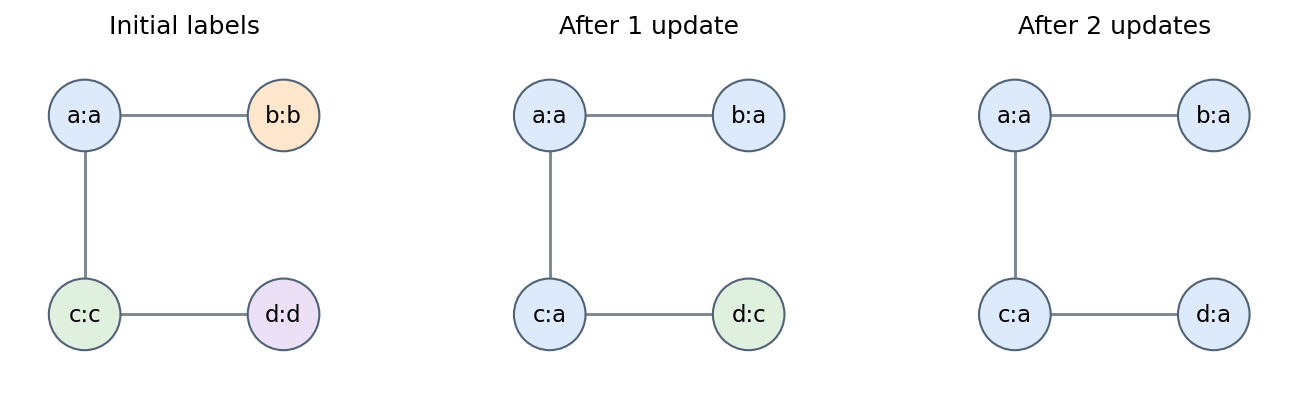

IDs are shortened: `d:c` means document `doc_d` has label `doc_c`.
Colors follow the labels; the edges stay fixed.


In [ ]:
# Initialize labels directly from Part 2.1's edges.
toy_initial_labels = (
    toy_edges.select(pl.col("src").alias("id"))
    .unique()
    .with_columns(pl.col("id").alias("component"))
)


**Implementing messages with Polars**

The graph is represented by two lazy tables: `edges(src, dst)` and
`labels(id, component)`. A message is a row containing a destination ID and
the source's current label.

| Algorithm operation | Polars operation |
| --- | --- |
| Send a label along each directed edge | [`join`](https://docs.pola.rs/api/python/stable/reference/lazyframe/api/polars.LazyFrame.join.html) the edge's `src` to the labels' `id`; keep `dst` as `id` and the source's `component` |
| Include each document's old label | [`polars.concat`](https://docs.pola.rs/api/python/stable/reference/api/polars.concat.html) the current labels and incoming messages |
| Choose the smallest label per document | Group by `id` and take [`min`](https://docs.pola.rs/api/python/stable/reference/expressions/api/polars.Expr.min.html) of `component` |

For example, `doc_c → doc_d` with source label `doc_c` produces the message
`(doc_d, doc_c)`. Both edge directions are already present, so the same join
handles both directions. These table operations are the complete update to implement.


<details>
<summary><strong>Hint: expected input and output</strong></summary>

**Example inputs**: `toy_edges` from Part 2.1 and the initial labels above

| `id` | Initial `component` |
| --- | --- |
| doc_a | doc_a |
| doc_b | doc_b |
| doc_c | doc_c |
| doc_d | doc_d |

```python
toy_one_step = label_step(toy_initial_labels, toy_edges)
```

**Expected output**: `toy_one_step`, the input to Part 2.3

| `id` | `component` |
| --- | --- |
| doc_a | doc_a |
| doc_b | doc_a |
| doc_c | doc_a |
| doc_d | doc_c |

All updates use the previous round’s labels. `doc_d` receives `doc_c` now;
`doc_a` reaches it on the next update. `doc_e` has no edges and needs no
component label.

</details>


In [ ]:
def label_step(labels, edges):
    """Update every document's component label using its neighbors.

    Args:
        labels (pl.LazyFrame): id (String), component (String).
        edges (pl.LazyFrame): src (String), dst (String), both directions.
    Returns:
        pl.LazyFrame: updated id (String), component (String).
    """
    # TODO: Form incoming (id, component) messages, then take each ID's minimum.
    # return <FILL IN>

    raise NotImplementedError("Complete this exercise.")


In [ ]:
"""Check one synchronous label update."""
toy_one_step = label_step(toy_initial_labels, toy_edges)
assert toy_one_step.collect().sort("id").rows() == [
    ("doc_a", "doc_a"), ("doc_b", "doc_a"),
    ("doc_c", "doc_a"), ("doc_d", "doc_c"),
]

def _check_label_propagation():
    # A six-node chain needs five synchronous updates to carry a to f.
    # x-y is a separate component and must never receive a's label.
    links = [("a", "b"), ("b", "c"), ("c", "d"), ("d", "e"), ("e", "f"), ("x", "y")]
    graph = pl.DataFrame(links + [(v, u) for u, v in links], schema=["src", "dst"], orient="row").lazy()
    initial = pl.LazyFrame({"id": list("abcdefxy"), "component": list("abcdefxy")})
    query = label_step(initial, graph)
    assert isinstance(query, pl.LazyFrame), "label_step must remain lazy"
    current = query.collect().sort("id")
    assert current.schema == {"id": pl.String, "component": pl.String}
    assert current.rows() == list(zip("abcdefxy", "aabcdexx")), "Use previous-round labels and retain old labels"
    for _ in range(4):
        current = label_step(current.lazy(), graph).collect().sort("id")
    assert current.rows() == [(node, "a" if node in "abcdef" else "x") for node in "abcdefxy"]
    stable = label_step(current.lazy(), graph).collect().sort("id")
    assert stable.equals(current), "Converged labels must remain unchanged"
    shuffled = label_step(initial.collect().reverse().lazy(), graph.collect().reverse().lazy()).collect()
    assert shuffled.sort("id").equals(query.collect().sort("id")), "Row order must not affect label updates"
    empty = label_step(initial.limit(0), graph.limit(0)).collect()
    assert empty.height == 0 and empty.schema == current.schema

_check_label_propagation()


### Part 2.3: Repeat until labels stop changing

Continue from `toy_one_step`, the output of Part 2.2, using the same `toy_edges`:

```text
repeat:
    updated = label_step(labels, edges)
    if updated equals labels:
        stop
    labels = updated
```

For this tiny example, collect and sort the labels by `id` before comparing them
with `DataFrame.equals`. Assign each changed result to `toy_labels` before the
next update. Return the final labels to lazy form with `.lazy()` for Part 2.4.

Store the number of updates performed by this loop in `local_updates`, including the unchanged update
that detects convergence. Part 3 repeats the same algorithm on Polars Cloud.


**Useful Polars APIs:**

- [`collect`](https://docs.pola.rs/api/python/stable/reference/lazyframe/api/polars.LazyFrame.collect.html) evaluates the tiny example.
- [`sort`](https://docs.pola.rs/api/python/stable/reference/dataframe/api/polars.DataFrame.sort.html) puts both tables in ID order.
- [`DataFrame.equals`](https://docs.pola.rs/api/python/stable/reference/dataframe/api/polars.DataFrame.equals.html) compares the complete label tables.


<details>
<summary><strong>Hint: expected input and output</strong></summary>

**Example input**: Part 2.2's `toy_one_step` and the unchanged `toy_edges`

| `id` | `component` before the loop |
| --- | --- |
| doc_a | doc_a |
| doc_b | doc_a |
| doc_c | doc_a |
| doc_d | doc_c |

**Expected output**: `toy_labels`

| `id` | `component` after convergence |
| --- | --- |
| doc_a | doc_a |
| doc_b | doc_a |
| doc_c | doc_a |
| doc_d | doc_a |

One update changes `doc_d`’s label to `doc_a`. The next update changes nothing, so
`local_updates == 2`. Keep the complete labels, including the unchanged documents.

</details>


In [ ]:
toy_labels = toy_one_step.collect().sort("id")
local_updates = 0
# TODO: Repeat label_step until labels stop changing; finish with a LazyFrame.
# <FILL IN>

raise NotImplementedError("Complete this exercise.")


In [ ]:
"""Check convergence, including the final unchanged update."""
assert toy_labels.collect().sort("id")["component"].to_list() == ["doc_a"] * 4
assert local_updates == 2

assert isinstance(toy_labels, pl.LazyFrame), "Return the final labels to lazy form"
assert toy_labels.collect().sort("id").rows() == [
    ("doc_a", "doc_a"), ("doc_b", "doc_a"), ("doc_c", "doc_a"), ("doc_d", "doc_a"),
], "Keep every participating document exactly once"
assert label_step(toy_labels, toy_edges).collect().sort("id").equals(
    toy_labels.collect().sort("id")
), "The final labels must be a fixed point"


### Part 2.4: Select a random representative

Keep one randomly selected document from each connected component. Also keep
every document absent from the component labels. Return a lazy table containing
`id` and the original `text`, using `seed` to make the selection reproducible.


<details>
<summary><strong>Hint</strong></summary>

One approach is to give each ID a priority with `pl.col("id").hash(seed=seed)`
and keep the lowest-priority document in each component. An anti join can remove
the other documents while preserving documents outside the graph.

</details>


For the toy example, keep any one of `doc_a`, `doc_b`, `doc_c`, and `doc_d`,
along with `doc_e`, which is outside the graph.


In [ ]:
def select_survivors(source, labels, seed=SEED):
    """Keep one seeded random representative per component and all unmatched documents.

    Args:
        source (pl.LazyFrame): id (String), text (String).
        labels (pl.LazyFrame): id (String), component (String).
        seed (int): random seed for reproducible selection.
    Returns:
        pl.LazyFrame: retained id (String), text (String).
    """
    # TODO: Replace <FILL IN> with your implementation.
    # return <FILL IN>

    raise NotImplementedError("Complete this exercise.")


In [ ]:
"""Check the selection requirements without prescribing the winning IDs."""
def _assert_survivors(source, labels, result):
    original = source.select("id", "text").collect()
    components = labels.collect()
    kept = set(result["id"].to_list())
    assert result.schema == {"id": pl.String, "text": pl.String}
    assert result.height == len(kept), "Return each retained document once"
    expected_text = original.filter(pl.col("id").is_in(list(kept))).sort("id")
    assert result.sort("id").equals(expected_text), "Preserve original IDs and text"
    unmatched = set(original["id"].to_list()) - set(components["id"].to_list())
    assert unmatched <= kept, "Keep every document outside the graph"
    for group in components.partition_by("component"):
        assert len(kept & set(group["id"].to_list())) == 1, "Keep exactly one document per component"

toy_deduplicated = select_survivors(toy_corpus, toy_labels).collect()
_assert_survivors(toy_corpus, toy_labels, toy_deduplicated)

def _check_survivor_selection():
    source = pl.LazyFrame({"id": [f"doc_{c}" for c in "abcdefg"], "text": [f"text {c}" for c in "abcdefg"]})
    labels = pl.LazyFrame({
        "id": [f"doc_{c}" for c in "abcdfg"],
        "component": ["doc_a"] * 4 + ["doc_f"] * 2,
    })
    for seed in [137, 0]:
        query = select_survivors(source, labels, seed=seed)
        assert isinstance(query, pl.LazyFrame), "select_survivors must remain lazy"
        result = query.collect().sort("id")
        _assert_survivors(source, labels, result)
        repeated = select_survivors(source, labels, seed=seed).collect().sort("id")
        assert result.equals(repeated), "The same inputs and seed must reproduce the selection"
    all_survive = select_survivors(source, labels.limit(0), seed=137).collect().sort("id")
    assert all_survive.equals(source.collect().sort("id")), "An empty graph must retain all documents"
    empty = select_survivors(source.limit(0), labels.limit(0)).collect()
    assert empty.height == 0 and empty.schema == {"id": pl.String, "text": pl.String}

_check_survivor_selection()


In [ ]:
"""Provided: a local end-to-end check. No corpus access or cloud cluster is needed."""
def _check_local_pipeline():
    source = pl.LazyFrame({
        "id": ["dup_a", "dup_b", "dup_c", "dup_d", "unique", "short_a", "short_b"],
        "text": ["aaaaaaaaaaaa", "aaaaaaaaaaaa", "bbbbbbbbbbbb", "bbbbbbbbbbbb", "cccccccccccc", "hi", "hi"],
    })
    # Exact duplicate pairs avoid a probabilistic near-match expectation.
    signatures = build_signatures(source, k=3, num_hashes=16, seed=137)
    buckets = create_lsh_buckets(signatures, num_bands=4, num_hashes=16)
    graph = sparse_edges(buckets).collect().lazy()
    assert graph.collect().sort("src", "dst").rows() == [
        ("dup_a", "dup_b"), ("dup_b", "dup_a"), ("dup_c", "dup_d"), ("dup_d", "dup_c"),
    ], "The full pipeline should identify exactly the two duplicate pairs"
    initial = pl.LazyFrame({
        "id": ["dup_a", "dup_b", "dup_c", "dup_d"],
        "component": ["dup_a", "dup_b", "dup_c", "dup_d"],
    })
    labels = label_step(initial, graph).collect().lazy()
    assert label_step(labels, graph).collect().sort("id").equals(labels.collect().sort("id"))
    result = select_survivors(source, labels, seed=137).collect().sort("id")
    _assert_survivors(source, labels, result)

    short_source = source.filter(pl.col("id").is_in(["short_a", "short_b"]))
    empty_graph = sparse_edges(create_lsh_buckets(build_signatures(short_source, 3, 16, 137), 4, 16)).collect()
    assert empty_graph.height == 0, "Short texts must not collide through empty signatures"
    no_labels = pl.LazyFrame(schema={"id": pl.String, "component": pl.String})
    assert select_survivors(short_source, no_labels).collect().sort("id").equals(short_source.collect().sort("id"))

_check_local_pipeline()
print("All local pipeline checks passed.")


## Part 3: Running on Polars Cloud

Your pipeline works locally. Now run it on the corpus, keeping the graph and
component labels on the cluster. You will submit the graph query, adapt your
convergence loop, and save the retained documents.

### Part 3.1: Connect to the cluster (provided)

Set `WORKSPACE` and `OUTPUT_ROOT` in Part 0, and start with `dataset = VERY_SMALL`.
Run the setup and helper cells below. The exercise cells include error handling
and shutdown; leave that scaffolding in place. After an error stops the cluster,
restart from Part 3.1.


In [ ]:
# Provided: authentication and cluster setup.
import polars_cloud as pc

assert pc.__version__ == "0.10.0", "Install polars-cloud==0.10.0, then restart the kernel."
assert WORKSPACE and OUTPUT_ROOT.startswith("s3://"), "Set WORKSPACE and OUTPUT_ROOT in Part 0."
assert dataset is None or dataset > 0
pc.authenticate()
ctx = pc.ComputeContext(
    workspace=WORKSPACE,
    cpus=1, memory=4, cluster_size=CLUSTER_SIZE,
    requirements=b"numpy",
    idle_timeout_mins=10, connection_mode="proxy",
)
ctx.start(wait=True)


In [ ]:
def execute_on_cloud(query, ctx):
    """Run a lazy query on the cluster and return its remote result."""
    try:
        return query.remote(context=ctx).distributed().execute()
    except BaseException:
        ctx.stop()
        raise


### Part 3.2: Build the remote graph

Execute the `edges` query from Part 2.1 and store a lazy reference to its remote
result in `remote_edges`. Initialize `labels` as a lazy `id, component` table
with one row per participating document, using its ID as its initial component
label. This is the same initialization you used in Part 2.2.


In [ ]:
try:
    # TODO: Execute the edge query and initialize labels from its remote result.
    # remote_edges = <FILL IN>
    # labels = <FILL IN>
    raise NotImplementedError("Complete this exercise.")
except BaseException:
    ctx.stop()
    raise


### Part 3.3: Find connected components

Adapt your convergence loop from Part 2.3 to run on the cluster.

<details>
<summary><strong>Hint: checking convergence</strong></summary>

Compare the old and updated labels by document ID. A remote query returning only
the IDs whose labels changed lets you use `n_rows_total` to decide when to stop.

</details>


In [ ]:
try:
    # TODO: Run label updates remotely until convergence.
    raise NotImplementedError("Complete this exercise.")
except BaseException:
    ctx.stop()
    raise


### Part 3.4: Save the deduplicated corpus

Use `select_survivors` with the original `documents` and converged `labels`.
Write the retained `id, text` table to `output_path` as Parquet files using
distributed execution. Wait for the write to finish and assign its completed
result to `output_result`.


In [ ]:
try:
    output_path = f"{OUTPUT_ROOT.rstrip('/')}/run_{uuid4().hex[:12]}/"
    # TODO: Select the survivors, write them to S3, and wait for completion.
    raise NotImplementedError("Complete this exercise.")
    print(f"Retained {output_result.n_rows_total:,} documents.")
    print("Output:", output_path)
except BaseException:
    ctx.stop()
    raise


In [ ]:
# Provided: verify the saved document count, then stop the cluster.
try:
    saved_count = pl.scan_parquet(f"{output_path}**/*.parquet").select(pl.len().alias("n"))
    mismatches = saved_count.filter(pl.col("n") != output_result.n_rows_total)
    assert execute_on_cloud(mismatches, ctx).n_rows_total == 0, "Saved document count does not match the write result."
    if dataset is None:  # FULL corpus only
        assert 4_200_000 <= output_result.n_rows_total <= 4_300_000, "Expected 4.2–4.3 million retained documents for FULL."
    print("Saved document count verified.")
finally:
    ctx.stop()


After `VERY_SMALL` succeeds, work up to `FULL`. When changing the dataset size,
rerun Part 0's configuration and scan cells and the planning cells in Parts 1–2,
then restart from Part 3.1. Each run writes to a new output directory.


## Part 4: Gloat


Congratualations!! You have just run a real-world data preprocessing task at-scale using Polars. If you wanted to scale up further, all you would need is to increase the cluster size (and increase your budget :P)

